# Building the LLM Architecture

In [2]:
pip install -q jax flax matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import jax
import jax.numpy as jnp
import flax.nnx as nnx

import matplotlib.pyplot as plt

# Creating the embedding layers

In [5]:
class TokenAndPositionEmbedding(nnx.Module):
    def __init__(self, maxlen, vocab_size, embed_dim, *, rngs):
        self.token_emb = nnx.Embed(vocab_size, embed_dim, rngs=rngs) # (vocab_size, D)
        self.pos_emb = nnx.Embed(maxlen, embed_dim, rngs=rngs) # (maxlen, D)

    def __call__(self, x):
        seq_len = x.shape[1]
        positions = jnp.arange(seq_len)[None, :] # (1, T, D)
        return self.token_emb(x) + self.pos_emb(positions) # (B, T, D)

In [7]:
def causal_attention_mask(seq_len):
    return jnp.tril(jnp.ones((seq_len, seq_len)))

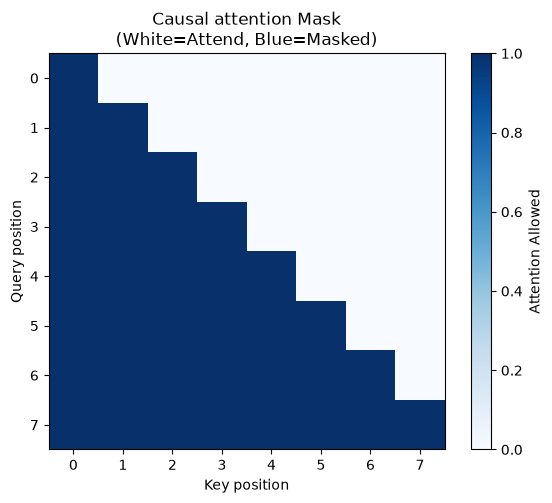

In [9]:
mask = causal_attention_mask(8)

plt.figure(figsize=(6,5))
plt.imshow(mask, cmap='Blues', interpolation='nearest')
plt.xlabel('Key position')
plt.ylabel('Query position')
plt.title('Causal attention Mask\n(White=Attend, Blue=Masked)')
plt.colorbar(label='Attention Allowed')
plt.tight_layout()
plt.show()

# Building the Transformer Block

In [11]:
class TransformerBlock(nnx.Module):

    def __init__(self, embed_dim, num_heads, ff_dim, *, rngs):
        self.attention = nnx.MultiHeadAttention(
            num_heads=num_heads,
            in_features=embed_dim,
            qkv_features=embed_dim,
            out_features=embed_dim,
            decode=False,
            rngs=rngs
        )

    def __call__(self, x, mask=None):
        attn_out = self.attention(x, mask=mask)
        x = x + attn_out
        return x